# 04 - Claim severity modelling: Gamma GLM vs LightGBM

## Goal of this notebook, in simple terms

Notebook 03 predicted *how many* claims a customer will have. Here we predict **how much one
claim costs on average** for a given customer profile. Multiplying the two (notebook 05) gives
the pure premium.

From notebook 02 we already expect this to be **hard**: the cost of an accident depends mostly on
circumstances we do not observe (who was hit, how badly, was anyone injured?), and many claims are
settled at fixed conventional amounts. So the goal here is also to find out **how much of the
cost is predictable at all** from the rating factors, and to avoid models that just learn noise.

Steps:
1. select the policies with claims, look at the target;
2. theory and fit of the Gamma GLM; statistical selection of the factors;
3. LightGBM with a Gamma objective, number of trees chosen by cross-validation;
4. compare on the same test set as notebook 03.

In [1]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import KFold

from motor_pricing import PROJECT_ROOT, RANDOM_STATE
from motor_pricing.data import load_processed
from motor_pricing.features import GLM_CATEGORICAL, GLM_NUMERIC, gbm_features
from motor_pricing.metrics import gamma_deviance, lift_table, double_lift_table
from motor_pricing.models import SeverityGLM, SeverityGBM, NullModel, SEV_GBM_PARAMS
from motor_pricing.validation import split_train_test, severity_scores
from motor_pricing.plotting import (set_style, save, plot_relativities, plot_lorenz, plot_lift,
                                    plot_double_lift, SERIES, INK_2)

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
df = load_processed()

## 1. The data for severity

**Goal:** build the severity dataset and understand the shape of the target.

* Only policies **with at least one claim** carry information on claim cost.
* The target is `AvgClaim` = capped claim amount / number of claims (single claims capped at
  €100,000, notebook 01).
* Each row is weighted by `ClaimNb`: a policy with 3 claims gives the average of 3 costs, which is
  3 times more reliable than a single cost.

We reuse **the same train/test split** as notebook 03 (same function, same seed), so that in
notebook 05 frequency and severity predictions on the test set refer to the same customers.

In [2]:
train, test = split_train_test(df, test_size=0.2)
sev_train, sev_test = train[train["ClaimNb"] > 0], test[test["ClaimNb"] > 0]
print(f"train: {len(sev_train):,} policies with claims, {sev_train['ClaimNb'].sum():,} claims")
print(f"test : {len(sev_test):,} policies with claims, {sev_test['ClaimNb'].sum():,} claims")
sev_train["AvgClaim"].describe(percentiles=[0.01, 0.1, 0.5, 0.9, 0.99]).to_frame().T

train: 19,955 policies with claims, 21,126 claims
test : 4,989 policies with claims, 5,279 claims


,count,mean,std,min,1%,10%,50%,90%,99%,max
AvgClaim,"19,955.0000","1,828.9119","5,315.8807",1.0000,40.9270,210.0600,"1,172.0000","2,757.8140","15,346.4848","100,000.0000"


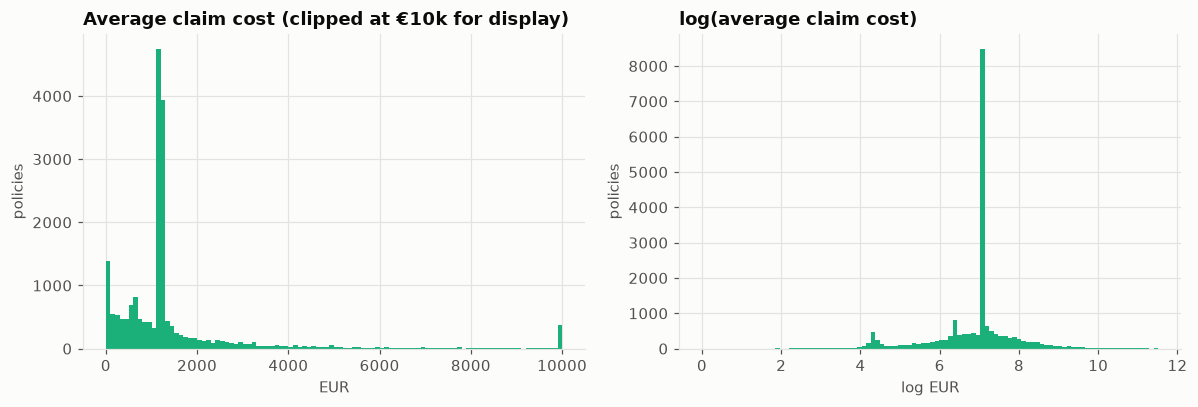

mean 1,829   median 1,172   coefficient of variation 2.91


In [3]:
y = sev_train["AvgClaim"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(y.clip(upper=10_000), bins=100, color=SERIES[2])
axes[0].set(title="Average claim cost (clipped at €10k for display)", xlabel="EUR", ylabel="policies")
axes[1].hist(np.log(y), bins=100, color=SERIES[2])
axes[1].set(title="log(average claim cost)", xlabel="log EUR", ylabel="policies")
plt.tight_layout(); save(fig, "04_target"); plt.show()
print(f"mean {y.mean():,.0f}   median {y.median():,.0f}   coefficient of variation {y.std() / y.mean():.2f}")

**What we see**

* ~20,000 training policies with claims (21,126 claims) - **27 times fewer rows** than for frequency.
* Strong right skew: median €1,172, mean €1,829, maximum €100,000 (the cap). The coefficient of
  variation (std / mean) is **2.9**: individual costs vary about three times as much as their mean.
* On the log scale the distribution is concentrated around €1,100-1,200 (the conventional
  flat-rate settlements seen in notebook 01) with long tails on both sides: tiny claims
  (1% are below €41) and large bodily-injury claims.

**Implication.** A model can only hope to explain a small part of this variability: most of it
is *within* any group of similar customers.

## 2. The Gamma GLM

### 2.1 Theory

**Why Gamma?** Claim costs are *positive*, *continuous* and *right-skewed*, and their spread
grows with their level (expensive groups are also more variable in euros). The **Gamma
distribution** has exactly these properties:

$$\mathbb{E}[Y_i] = \mu_i, \qquad \operatorname{Var}(Y_i) = \phi\,\mu_i^2$$

i.e. a **constant coefficient of variation** $\sqrt\phi$: the standard deviation is proportional
to the mean. An error of €500 matters a lot for a group averaging €1,000 but little for one
averaging €20,000 - the Gamma deviance measures errors in *relative* terms.

**Model.** With a log link, as for frequency:

$$\log \mu_i = \beta_0 + \sum_j \beta_j x_{ij} \quad\Longrightarrow\quad \mu_i = e^{\beta_0}\prod_j e^{\beta_j x_{ij}}$$

so the coefficients are again **multiplicative relativities**, and the final tariff
frequency × severity is still a product of relativities.

**Weights.** If policy $i$ has $n_i$ claims, $Y_i$ is the average of $n_i$ independent costs and
$\operatorname{Var}(Y_i) = \phi\mu_i^2/n_i$: $n_i$ enters as a *variance weight*.

**Why not a linear regression on log(cost)?** It would model $\mathbb{E}[\log Y]$, and
$e^{\mathbb{E}[\log Y]}$ is *not* $\mathbb{E}[Y]$ (it is smaller - Jensen's inequality), so it
systematically under-estimates the average cost unless corrected. The Gamma GLM models the mean
cost directly.

**Dispersion.** Unlike Poisson, the Gamma has a free dispersion $\phi$, estimated from the data;
tests of significance therefore use the **F distribution** instead of the chi-square.

### 2.2 Full model and factor selection

**Goal:** start with all the rating factors used for frequency and test, for each factor,
whether removing it makes the fit significantly worse.

**Method (drop-one F-test).** For each factor we refit the GLM without it. The increase in
deviance $\Delta D$ over the $k$ removed parameters, scaled by the dispersion, follows under
$H_0$ ("the factor has no effect") an F distribution:
$$F = \frac{\Delta D / k}{\hat\phi} \sim F_{k,\,n-p}$$
A small p-value means the factor carries real information about claim cost.

In [4]:
full = SeverityGLM().fit(train)
res = full.result_
print(f"parameters: {len(res.params)}  deviance: {res.deviance:,.1f}  null deviance: {res.null_deviance:,.1f}")
print(f"estimated dispersion phi: {res.scale:.2f}  ->  coefficient of variation sqrt(phi) = {np.sqrt(res.scale):.2f}")

rows = []
for f in GLM_CATEGORICAL + GLM_NUMERIC:
    reduced = SeverityGLM([c for c in GLM_CATEGORICAL if c != f], [c for c in GLM_NUMERIC if c != f]).fit(train)
    k = int(round(reduced.result_.df_resid - res.df_resid))
    F = (reduced.result_.deviance - res.deviance) / k / res.scale
    rows.append({"factor": f.replace("GLM", ""), "params removed": k, "deviance increase": reduced.result_.deviance - res.deviance,
                 "F": F, "p_value": stats.f.sf(F, k, res.df_resid)})
drop_one = pd.DataFrame(rows).set_index("factor").sort_values("p_value")
drop_one

parameters: 48  deviance: 26,946.0  null deviance: 27,544.6
estimated dispersion phi: 7.70  ->  coefficient of variation sqrt(phi) = 2.77


,params removed,deviance increase,F,p_value
factor,,,,
DrivAge,6,126.6136,2.7423,0.0115
BonusMalus,1,40.1615,5.2191,0.0224
Region,21,219.9893,1.3613,0.1244
VehBrand,10,96.9186,1.2595,0.2473
VehPower,5,48.5553,1.2620,0.2773
VehAge,2,10.5984,0.6886,0.5023
VehGas,1,2.4077,0.3129,0.5759
LogDensity,1,0.0538,0.0070,0.9333


**Interpretation**

* The estimated dispersion is $\hat\phi \approx 7.7$, i.e. a coefficient of variation of ~2.8 *after*
  accounting for all factors - the model barely reduces the noise (deviance 26,946 vs 27,545 for the
  null model: **2.2% of the in-sample deviance** explained, with 47 parameters).
* Only **driver age** (p = 0.012) and **bonus-malus** (p = 0.022) are significant at the 5% level.
  Region, brand, power, vehicle age, fuel and density show no evidence of an effect on cost.

*Real-world meaning:* once an accident happens, its cost depends little on the car or where the
driver lives, but somewhat on *who* drives (age, past behaviour) - consistent with notebook 02.

*Caveat:* the Gamma assumption is not perfect here (spikes at fixed amounts, heavy tails), so
p-values are approximate. That is why we also check predictive performance directly below.

### 2.3 Full vs reduced GLM - cross-validation on the training set

**Goal:** p-values answer "is there an effect?", but our question is "which model *predicts*
better on new customers?". We compare the full GLM and the reduced one (driver age + bonus-malus)
with 5-fold cross-validation on the training claims.

In [5]:
SELECTED_CAT, SELECTED_NUM = ["DrivAgeGLM"], ["BonusMalusGLM"]
kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for fold, (a, b) in enumerate(kf.split(sev_train), start=1):
    tr, va = sev_train.iloc[a], sev_train.iloc[b]
    null_va = NullModel("AvgClaim", "ClaimNb").fit(tr).predict(va)
    for name, m in {"GLM full": SeverityGLM(),
                    "GLM reduced": SeverityGLM(SELECTED_CAT, SELECTED_NUM)}.items():
        s = severity_scores(va, m.fit(tr).predict(va), null_va)
        cv_rows.append({"model": name, "fold": fold, **s})
cv_glm = pd.DataFrame(cv_rows)
cv_glm.groupby("model")[["gamma_deviance", "deviance_explained", "gini"]].agg(["mean", "std"])

gamma_deviance        deviance_explained          gini       
                      mean    std               mean    std   mean    std
model                                                                    
GLM full            1.3100 0.0297            -0.0047 0.0094 0.0457 0.0221
GLM reduced         1.3020 0.0299             0.0014 0.0064 0.0305 0.0179

**Interpretation**

* The **full GLM has a *negative* cross-validated deviance explained (-0.5%)**: on new data it
  predicts *worse* than simply using the average cost for everybody. Its 47 parameters fit noise of
  the training folds - textbook **over-fitting**.
* The **reduced GLM** (driver age + bonus-malus, 8 parameters) is better in deviance (1.302 vs
  1.310) and positive, although tiny (+0.14%). The full model ranks slightly better (Gini 0.046 vs
  0.031) but with huge fold-to-fold variability (std 0.02).

**Decision:** we keep the **reduced GLM**: it is statistically justified (F-tests), predicts at
least as well, and is far simpler (*parsimony*). Fewer parameters also mean more stable premiums
from one year to the next.

### 2.4 The selected severity GLM

In [6]:
glm = SeverityGLM(SELECTED_CAT, SELECTED_NUM).fit(train)
rel = glm.relativities()
print(f"dispersion phi = {glm.result_.scale:.2f}")
rel[["coef", "std_err", "p_value", "relativity", "ci_low", "ci_high"]]

dispersion phi = 8.27


,coef,std_err,p_value,relativity,ci_low,ci_high
const,7.3489,0.0793,0.0000,"1,554.5079","1,330.6945","1,815.9651"
BonusMalusGLM,0.0021,0.0012,0.0828,1.0021,0.9997,1.0045
DrivAgeGLM[18-20],0.3087,0.1438,0.0318,1.3616,1.0273,1.8048
DrivAgeGLM[21-25],0.0299,0.0972,0.7584,1.0303,0.8517,1.2465
DrivAgeGLM[26-30],0.0106,0.0808,0.8955,1.0107,0.8627,1.1840
DrivAgeGLM[31-40],0.0537,0.0573,0.3486,1.0551,0.9431,1.1805
DrivAgeGLM[41-50],-0.0160,0.0540,0.7673,0.9841,0.8853,1.0941
DrivAgeGLM[71+],0.2478,0.0885,0.0051,1.2812,1.0773,1.5238


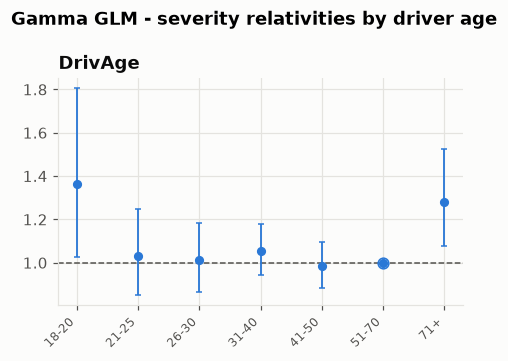

severity multiplier vs BM = 50: {np.int64(50): np.float64(1.0), np.int64(60): np.float64(1.021), np.int64(70): np.float64(1.043), np.int64(80): np.float64(1.066), np.int64(90): np.float64(1.089), np.int64(100): np.float64(1.112), np.int64(110): np.float64(1.136), np.int64(120): np.float64(1.16), np.int64(130): np.float64(1.185), np.int64(140): np.float64(1.21), np.int64(150): np.float64(1.236)}


In [7]:
plot_relativities(glm, ["DrivAgeGLM"], ncols=1,
                  title="Gamma GLM - severity relativities by driver age", name="04_glm_relativities")
bm = np.arange(50, 151, 10)
print("severity multiplier vs BM = 50:", dict(zip(bm, np.round(np.exp(rel.loc['BonusMalusGLM', 'coef'] * (bm - 50)), 3))))

**Reading the severity GLM**

* **Base cost** $e^{\beta_0} \approx €1,555$: average claim for the reference group (driver 51-70) at BM = 0
  (to be read together with the BM term: at BM = 50 the base is about €1,555 × 1.11 ≈ €1,720).
* **Driver age**: claims caused by **18-20-year-olds cost 36% more** (relativity 1.36, CI 1.03-1.80) and
  by **drivers over 70 cost 28% more** (1.28, CI 1.08-1.52). All middle age bands are statistically
  indistinguishable from the reference (relativities 0.98-1.06, p > 0.3).
* **Bonus-malus**: +0.2% per point, i.e. **+11% at BM 100 vs 50** - small and borderline
  (p = 0.08 in this reduced model; CI includes 1.0).

*Mathematical meaning:* severity relativities are much closer to 1 than frequency relativities,
and their confidence intervals are much wider - few observations, a lot of noise.

*Real-world meaning:* very young drivers cause more *serious* accidents (speed, bodily injury), and
elderly drivers too (slower reactions; injuries to older people are more costly). For the
premium, the age effect now enters **twice**: young drivers have both more claims *and* more
expensive ones.

## 3. LightGBM with a Gamma objective

### 3.1 Theory and tuning strategy

Same boosting machinery as in notebook 03, with the **Gamma deviance** as loss (log link), the
average claim as target and `ClaimNb` as weight. With only ~21,000 noisy observations the main
risk is **over-fitting**: each additional tree may learn noise. We therefore use very small trees
(3-7 leaves), large minimum leaf sizes, strong L2 regularisation and a small learning rate.

The number of trees is the key parameter. With so few claims, the 10% internal early-stopping set
used for frequency (~2,000 claims) is too noisy to choose it reliably. Instead we compute, by
**5-fold cross-validation on the training claims**, the validation deviance after every 25 trees,
for a few tree shapes, and pick the combination with the lowest average deviance.

search time 19s


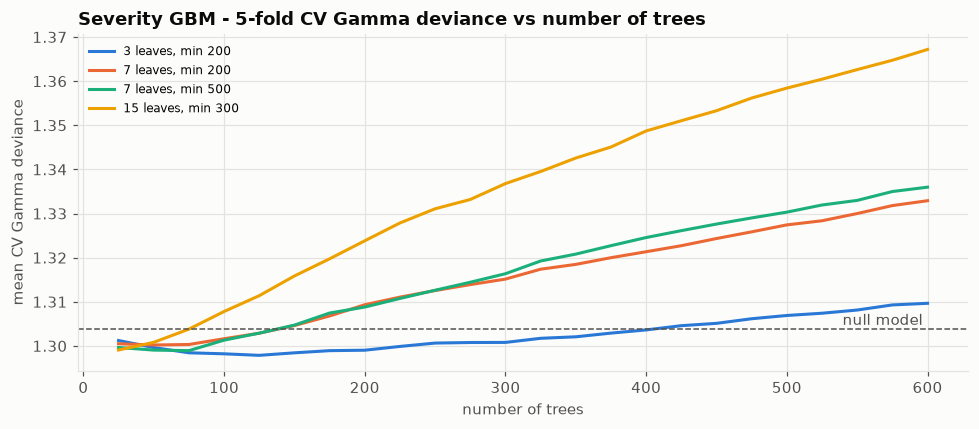

best: 3 leaves, min 200 with 125 trees, CV deviance 1.2979 (null 1.3039)


,"3 leaves, min 200","7 leaves, min 200","7 leaves, min 500","15 leaves, min 300"
25,1.3012,1.3005,1.2996,1.2991
50,1.2996,1.3002,1.2991,1.3008
100,1.2982,1.3016,1.3013,1.3078
150,1.2984,1.3046,1.3047,1.3158
200,1.2990,1.3093,1.3088,1.3238
300,1.3008,1.3151,1.3164,1.3368
400,1.3036,1.3213,1.3246,1.3487
600,1.3097,1.3329,1.3360,1.3672


In [8]:
from lightgbm import LGBMRegressor

configs = [dict(num_leaves=3, min_child_samples=200), dict(num_leaves=7, min_child_samples=200),
           dict(num_leaves=7, min_child_samples=500), dict(num_leaves=15, min_child_samples=300)]
checkpoints = list(range(25, 601, 25))
curves = {}
t0 = time.time()
for ci, cfg in enumerate(configs):
    params = {**SEV_GBM_PARAMS, **cfg, "n_estimators": max(checkpoints), "random_state": RANDOM_STATE}
    dev = np.zeros((5, len(checkpoints)))
    for fold, (a, b) in enumerate(kf.split(sev_train)):
        tr, va = sev_train.iloc[a], sev_train.iloc[b]
        m = LGBMRegressor(**params).fit(gbm_features(tr), tr["AvgClaim"], sample_weight=tr["ClaimNb"])
        Xva = gbm_features(va)
        for j, n in enumerate(checkpoints):
            dev[fold, j] = gamma_deviance(va["AvgClaim"], m.predict(Xva, num_iteration=n), va["ClaimNb"])
    curves[f"{cfg['num_leaves']} leaves, min {cfg['min_child_samples']}"] = dev.mean(axis=0)
print(f"search time {time.time() - t0:.0f}s")

fig, ax = plt.subplots(figsize=(9, 4))
for i, (label, c) in enumerate(curves.items()):
    ax.plot(checkpoints, c, color=SERIES[i], label=label)
null_cv = np.mean([gamma_deviance(sev_train.iloc[b]["AvgClaim"],
                                  np.full(len(b), np.average(sev_train.iloc[a]["AvgClaim"], weights=sev_train.iloc[a]["ClaimNb"])),
                                  sev_train.iloc[b]["ClaimNb"]) for a, b in kf.split(sev_train)])
ax.axhline(null_cv, color=INK_2, ls="--", lw=1); ax.text(checkpoints[-1], null_cv, "null model ", ha="right", va="bottom", color=INK_2)
ax.set(title="Severity GBM - 5-fold CV Gamma deviance vs number of trees", xlabel="number of trees", ylabel="mean CV Gamma deviance")
ax.legend(fontsize=8); plt.tight_layout(); save(fig, "04_gbm_cv_curve"); plt.show()

cv_table = pd.DataFrame(curves, index=checkpoints)
best_label = cv_table.min().idxmin(); best_n = int(cv_table[best_label].idxmin())
best_cfg = configs[list(curves).index(best_label)]
print(f"best: {best_label} with {best_n} trees, CV deviance {cv_table[best_label].min():.4f} (null {null_cv:.4f})")
cv_table.loc[[25, 50, 100, 150, 200, 300, 400, 600]]

**Interpretation of the curves**

* Every configuration improves on the null model only for the first few dozen trees and then gets
  **worse and worse** as trees are added: each new tree learns more noise than signal. The bigger
  the trees (15 leaves), the faster the degradation.
* The best choice is the **smallest trees (3 leaves) with 125 trees**: CV deviance 1.2979 vs 1.3039
  for the null model, i.e. **~0.5% of deviance explained** - slightly more than the reduced GLM in CV
  (0.1%), but tiny in absolute terms.

*Mathematical meaning:* a 3-leaf tree splits on at most 2 variables, so the model is almost additive:
very limited interactions. The data simply does not support complex structure for severity.
This curve is a direct visualisation of the **bias-variance trade-off**.

In [9]:
best_params = {**best_cfg, "n_estimators": best_n}
(PROJECT_ROOT / "models").mkdir(exist_ok=True)
with open(PROJECT_ROOT / "models" / "severity_gbm_params.json", "w") as f:
    json.dump(best_params, f, indent=2)
gbm = SeverityGBM(early_stopping_rounds=0, **best_params).fit(train)
print("final severity GBM:", best_params)

final severity GBM: {'num_leaves': 3, 'min_child_samples': 200, 'n_estimators': 125}


## 4. Comparison on the test set

Metrics as in notebook 03, adapted to severity: **Gamma deviance** (weighted by number of claims),
deviance explained vs the null model (same average cost for everybody), **Gini** of the ranking of
claim costs, and **balance** (predicted / observed total capped cost of the test claims).

In [10]:
null = NullModel("AvgClaim", "ClaimNb").fit(sev_train)
models = {"Null": null, "GLM": glm, "GBM": gbm}
preds = {k: m.predict(sev_test) for k, m in models.items()}
results = pd.DataFrame({k: severity_scores(sev_test, p, preds["Null"]) for k, p in preds.items()}).T
results.loc["GLM full (all factors)"] = severity_scores(sev_test, full.predict(sev_test), preds["Null"])
results

,gamma_deviance,deviance_explained,gini,predicted_cost / observed_cost
Null,1.3824,0.0000,-0.0323,0.9645
GLM,1.3605,0.0158,0.0671,0.9644
GBM,1.3661,0.0118,0.0733,0.9544
GLM full (all factors),1.3647,0.0128,0.0798,0.9638


**Interpretation**

* On the test set all models are only slightly better than the null model: deviance explained
  **1.6% (reduced GLM)**, **1.2% (GBM)** and 1.3% (full GLM). Gini indices are around **0.07-0.08**
  (vs 0.28-0.32 for frequency).
* Test values are higher than the cross-validated ones (0.1-0.5%): with only ~5,000 test claims
  a single test set is noisy (the CV standard deviation across folds was ~0.6-0.9 points). The
  honest conclusion is: **the models are tied**, and severity is only weakly predictable.
* **Balance ≈ 0.96 for every model, including the null**: the test claims happen to be ~4% more
  expensive on average than the training ones - sampling variation, not model bias.

*Real-world meaning:* for this portfolio, **frequency is where segmentation happens**. Severity
contributes a modest correction (mostly by driver age), and a sophisticated model does not help.

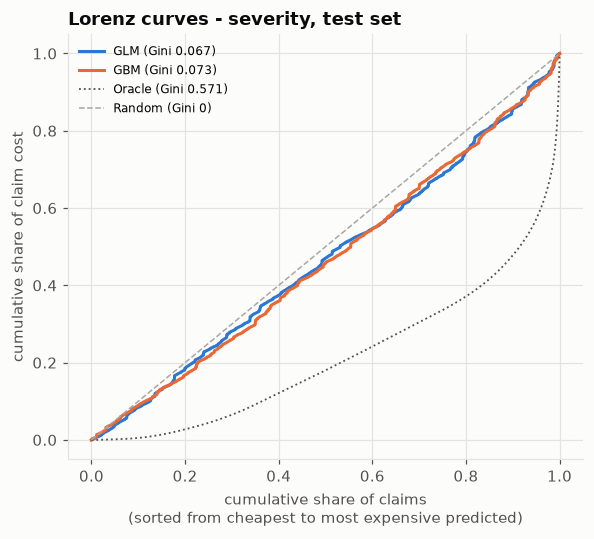

In [11]:
ys, ws = sev_test["AvgClaim"].to_numpy(), sev_test["ClaimNb"].to_numpy()
fig, ax = plt.subplots(figsize=(5.5, 5))
plot_lorenz(ys, {"GLM": preds["GLM"], "GBM": preds["GBM"]}, ws, title="Lorenz curves - severity, test set", ax=ax)
ax.set_xlabel("cumulative share of claims\n(sorted from cheapest to most expensive predicted)")
ax.set_ylabel("cumulative share of claim cost")
plt.tight_layout(); save(fig, "04_lorenz"); plt.show()

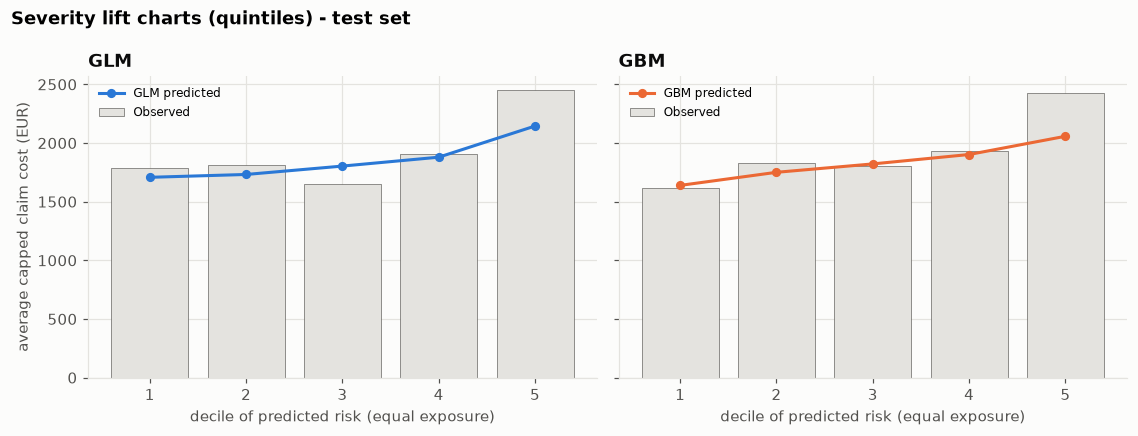

GLM                                     GBM                        \
        weight  predicted   observed   lift     weight  predicted   observed   
bin                                                                            
1   1,054.0000 1,707.7000 1,789.4000 0.9000 1,055.0000 1,638.8000 1,616.7000   
2   1,057.0000 1,731.9000 1,809.7000 0.9000 1,056.0000 1,750.4000 1,832.7000   
3   1,056.0000 1,803.5000 1,650.5000 0.9000 1,056.0000 1,821.9000 1,800.1000   
4   1,056.0000 1,879.2000 1,910.4000 1.0000 1,056.0000 1,902.1000 1,928.6000   
5   1,056.0000 2,144.8000 2,448.9000 1.3000 1,056.0000 2,057.5000 2,430.7000   

            
      lift  
bin         
1   0.8000  
2   1.0000  
3   0.9000  
4   1.0000  
5   1.3000

In [12]:
lifts = {k: lift_table(ys, preds[k], ws, n_bins=5) for k in ["GLM", "GBM"]}
plot_lift(lifts, "Severity lift charts (quintiles) - test set", "average capped claim cost (EUR)", name="04_lift")
pd.concat(lifts, axis=1).round(1)

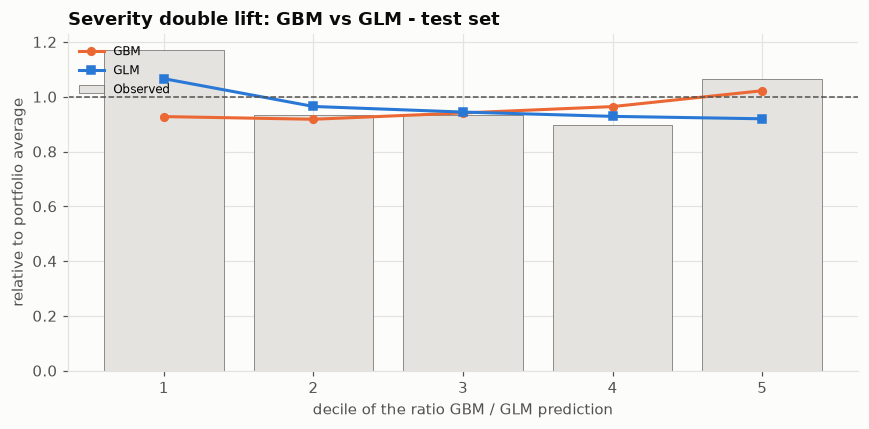

,weight,observed,model_a,model_b
bin,,,,
1,"1,055.0000",1.1700,0.9280,1.0660
2,"1,055.0000",0.9340,0.9180,0.9640
3,"1,057.0000",0.9340,0.9410,0.9440
4,"1,056.0000",0.8970,0.9640,0.9280
5,"1,056.0000",1.0650,1.0220,0.9190


In [13]:
dl = double_lift_table(ys, preds["GBM"], preds["GLM"], ws, n_bins=5)
plot_double_lift(dl, "GBM", "GLM", "Severity double lift: GBM vs GLM - test set", name="04_double_lift")
dl.round(3)

**Interpretation**

* **Lift (quintiles)**: observed average cost is flat in quintiles 1-4 (~€1,600-1,930) and higher only
  in quintile 5 (~€2,430-2,450): both models identify an expensive group (largely young and old
  drivers) but cannot order the rest. Both *under-predict* the top quintile.
* **Double lift**: no consistent winner - the GLM is closer in quintile 1, the GBM in quintile 5,
  and the differences are within noise.

Severity confirms the EDA: low signal, the GBM's flexibility does not pay off. We will use **both**
severity models in notebook 05 to build pure premiums, and see that the overall pure premium
comparison is driven by frequency.

## 5. Conclusions

| | Reduced Gamma GLM (age + BM) | LightGBM (Gamma, 3 leaves, 125 trees) |
|---|---|---|
| 5-fold CV deviance explained (train) | 0.1% | 0.5% |
| Test deviance explained | **1.6%** | 1.2% |
| Test Gini | 0.067 | 0.073 |
| Parameters / complexity | 8 parameters | 125 small trees |

* The cost of a claim is **largely unpredictable** from rating factors: ~1% of deviance explained.
* Only **driver age** (18-20: +36%, 71+: +28%) and, marginally, **bonus-malus** affect severity.
* A complex model **over-fits** quickly: both the full GLM and large-tree GBMs are worse than the null
  model out-of-sample. Strong regularisation (variable selection, tiny trees, few iterations) is essential.
* The two final severity models are statistically **tied**. In practice the simple GLM would be
  preferred for severity.

Next: **05 - Model comparison with cross-validation and pure premium**.